Import Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.fft import fft, fftfreq

Load WAV Audio File

In [ ]:
!wget https://www.samplefiles.online/files/sample-speech-short.wav -O audio.wav

--2026-11-25 03:41:21--  https://www.samplefiles.online/files/sample-speech-short.wav
Resolving www.samplefiles.online (www.samplefiles.online)... 216.150.16.193, 216.150.1.193
Connecting to www.samplefiles.online (www.samplefiles.online)|216.150.16.193|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 164126 (160K) [audio/wave]
Saving to: ‘audio.wav’

audio.wav           100%[===================>] 160.28K  --.-KB/s    in 0.01s   

2026-11-25 03:41:21 (10.8 MB/s) - ‘audio.wav’ saved [164126/164126]



Read WAV Audio File

In [ ]:
Fs, audio = wavfile.read('audio.wav')

print("Sampling Frequency:", Fs)
print("Audio Shape:", audio.shape)
print("Data Type:", audio.dtype)
print("Duration:", len(audio) / Fs, "seconds")

Sampling Frequency: 16000
Audio Shape: (82024,)
Data Type: int16
Duration: 5.1265 seconds


Plot Original Audio

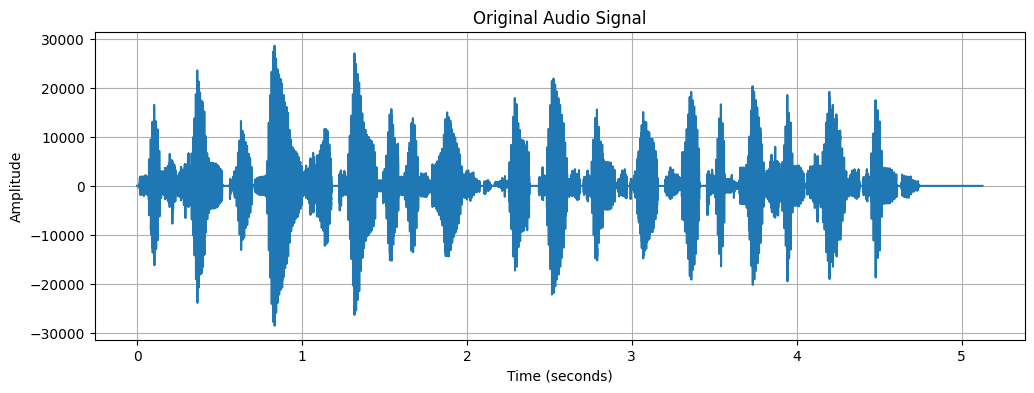

In [ ]:
# t = np.arange(len(audio))
t = np.arange(len(audio)) / Fs

plt.figure(figsize=(12, 4))
plt.plot(t, audio)

plt.title("Original Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.show()

Generate & Add Sinusoidal Noise

In [ ]:
f0 = 50
A = 3000

n = np.arange(len(audio))

noise = A * np.sin(2 * np.pi * f0 * n / Fs)

audio_float = audio.astype(float)

noisy_audio = audio_float + noise

Plot Clean vs Noisy Audio

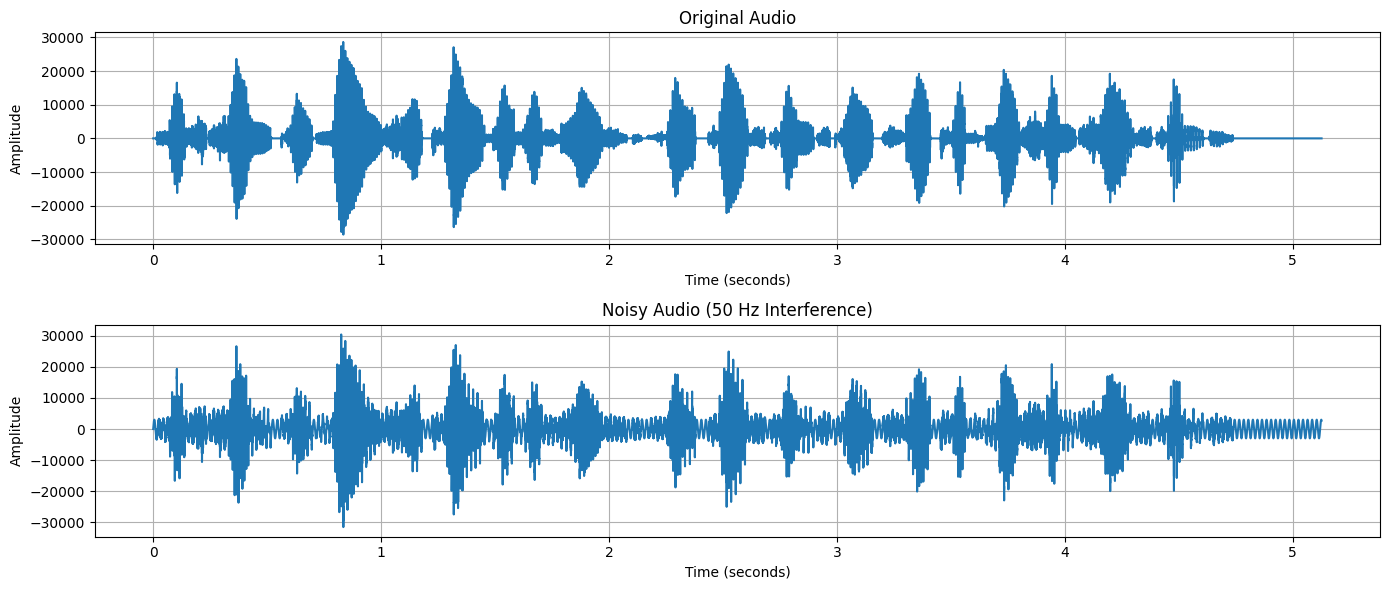

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(2, 1, 1)
plt.plot(t, audio_float)
plt.title("Original Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(t, noisy_audio)
plt.title("Noisy Audio (50 Hz Interference)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

Frequency Analysis

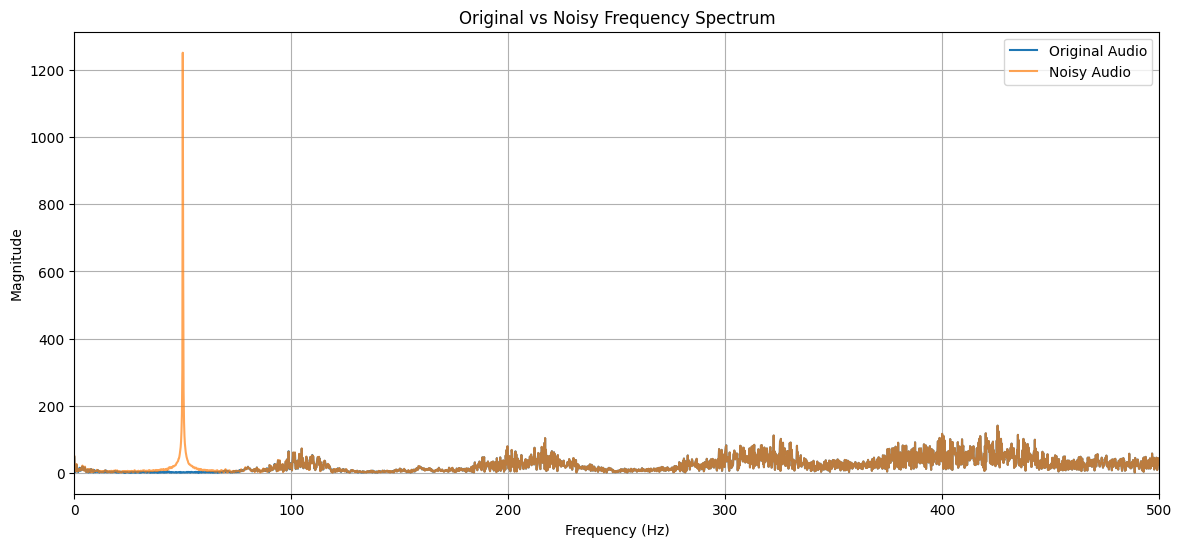

In [ ]:
N = len(audio)

X = fft(audio_float)
Y = fft(noisy_audio)

frequencies = fftfreq(N, 1/Fs)

X_magnitude = np.abs(X) / N
Y_magnitude = np.abs(Y) / N

positive = frequencies >= 0

plt.figure(figsize=(14, 6))

plt.plot(frequencies[positive],
         X_magnitude[positive],
         label="Original Audio")

plt.plot(frequencies[positive],
         Y_magnitude[positive],
         label="Noisy Audio",
         alpha=0.7)

plt.xlim(0, 500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Original vs Noisy Frequency Spectrum")
plt.legend()
plt.grid()
plt.show()

In [ ]:
diff = (Y_magnitude - X_magnitude)[positive]
f_pos = frequencies[positive]
print("Detected interference frequency:", f_pos[np.argmax(diff)], "Hz")

Detected interference frequency: 49.93660392080367 Hz


Prepare the Output WAV File

In [ ]:
# wavfile.write(
#     'noisy_audio.wav',
#     Fs,
#     noisy_audio.astype(np.float32)
# )

# print("Noisy audio saved successfully!")

out_noisy = np.clip(noisy_audio, -32768, 32767).astype(np.int16)
wavfile.write('noisy_audio.wav', Fs, out_noisy)

print("Noisy audio saved successfully!")

Noisy audio saved successfully!


Download the File

In [ ]:
from google.colab import files

files.download('noisy_audio.wav')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Student 4


In [ ]:
from scipy.signal import lfilter, freqz
from IPython.display import Audio, display

Design the Notch Filter

In [ ]:
r = 0.995
w0 = 2 * np.pi * f0 / Fs

b = np.array([1, -2*np.cos(w0), 1])
a = np.array([1, -2*r*np.cos(w0), r**2])

print("w0 =", w0)
print("b =", b)
print("a =", a)

w0 = 0.019634954084936207
b = [ 1.         -1.99961448  1.        ]
a = [ 1.         -1.98961641  0.990025  ]


Zeros, Poles and Stability

In [ ]:
zeros = np.roots(b)
poles = np.roots(a)

print("Zeros:", zeros)
print("|Zeros| =", np.abs(zeros))
print("Poles:", poles)
print("|Poles| =", np.abs(poles))
print("Stable?", np.all(np.abs(poles) < 1))

Zeros: [0.99980724+0.01963369j 0.99980724-0.01963369j]
|Zeros| = [1. 1.]
Poles: [0.9948082+0.01953552j 0.9948082-0.01953552j]
|Poles| = [0.995 0.995]
Stable? True


In [ ]:
filtered_audio = lfilter(b, a, noisy_audio)

Filter Frequency Response

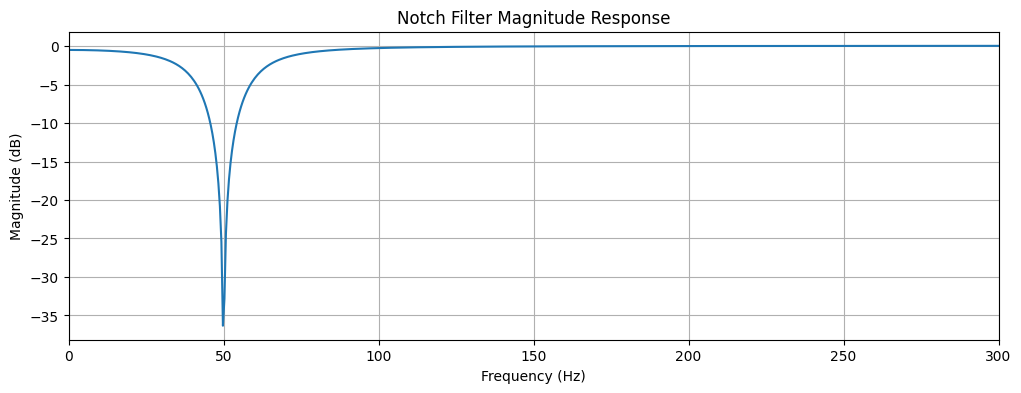

In [ ]:
w, h = freqz(b, a, worN=16384, fs=Fs)

plt.figure(figsize=(12, 4))
plt.plot(w, 20*np.log10(np.abs(h) + 1e-12))
plt.xlim(0, 300)
plt.title("Notch Filter Magnitude Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid()
plt.show()

Spectrum Comparison

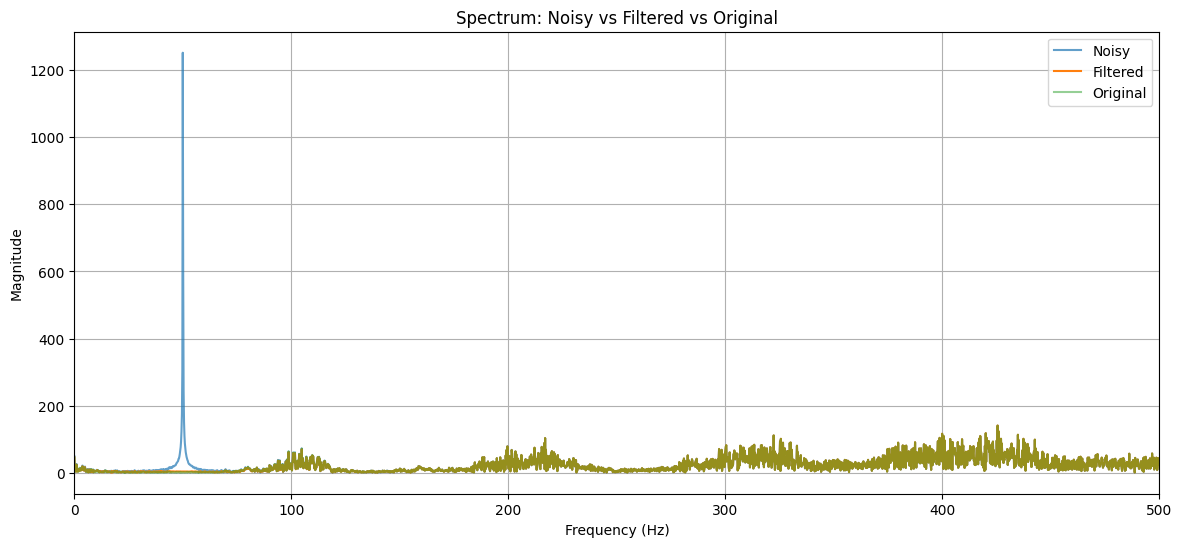

In [ ]:
Z = fft(filtered_audio)
Z_magnitude = np.abs(Z) / N

plt.figure(figsize=(14, 6))
plt.plot(frequencies[positive], Y_magnitude[positive], label="Noisy", alpha=0.7)
plt.plot(frequencies[positive], Z_magnitude[positive], label="Filtered")
plt.plot(frequencies[positive], X_magnitude[positive], label="Original", alpha=0.5)
plt.xlim(0, 500)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Spectrum: Noisy vs Filtered vs Original")
plt.legend()
plt.grid()
plt.show()

Quantitative Evaluation

In [ ]:
def mag_at(sig, f_target, bw=1):
    S = np.abs(fft(sig)) / len(sig)
    f = fftfreq(len(sig), 1/Fs)
    return S[np.abs(f - f_target) <= bw].max()

before = mag_at(noisy_audio, f0)
after  = mag_at(filtered_audio, f0)
print(f"Magnitude at {f0} Hz: noisy = {before:.1f}, filtered = {after:.2f}")
print(f"Reduction = {20*np.log10(before/after):.1f} dB")

def snr(y):
    return 10*np.log10(np.sum(audio_float**2) / np.sum((y - audio_float)**2))

print(f"SNR noisy    = {snr(noisy_audio):.1f} dB")
print(f"SNR filtered = {snr(filtered_audio):.1f} dB")

Magnitude at 50 Hz: noisy = 1251.8, filtered = 3.71
Reduction = 50.6 dB
SNR noisy    = 2.9 dB
SNR filtered = 21.3 dB


Time Domain Comparison

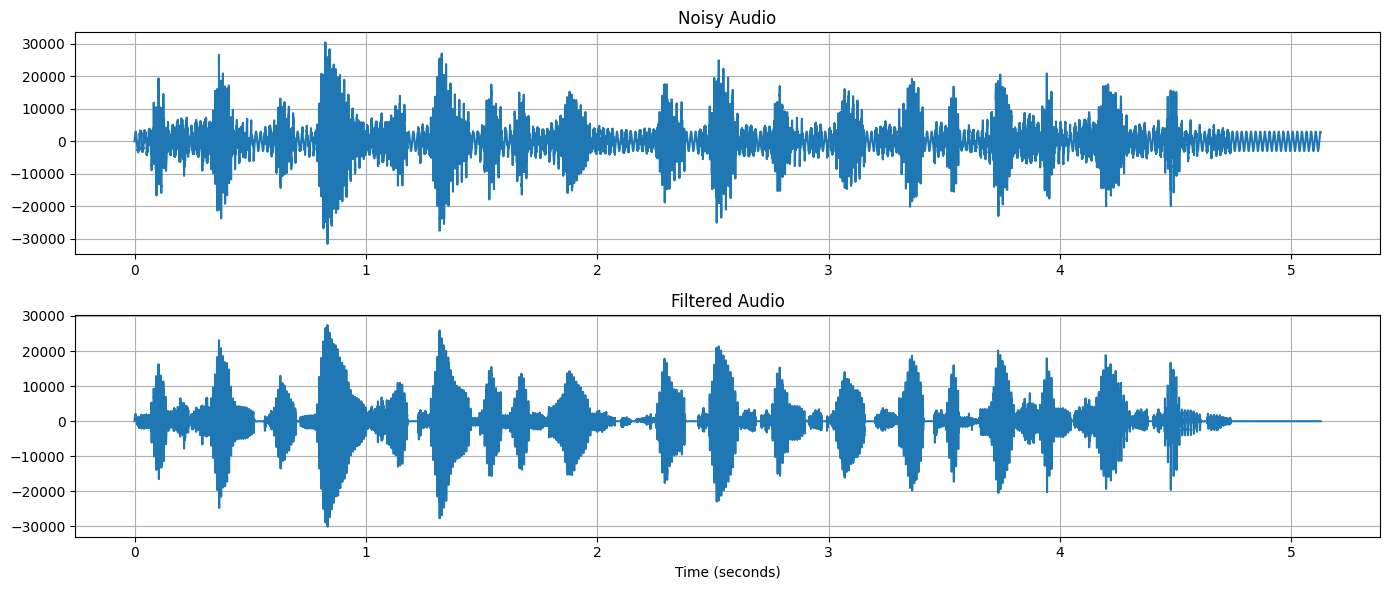

In [ ]:
time = np.arange(N) / Fs

plt.figure(figsize=(14, 6))
plt.subplot(2, 1, 1)
plt.plot(time, noisy_audio)
plt.title("Noisy Audio")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(time, filtered_audio)
plt.title("Filtered Audio")
plt.xlabel("Time (seconds)")
plt.grid()

plt.tight_layout()
plt.show()

save

In [ ]:
out = np.clip(filtered_audio, -32768, 32767).astype(np.int16)
wavfile.write("filtered_audio.wav", Fs, out)
print("Filtered audio saved!")

print("Noisy:")
display(Audio(noisy_audio, rate=Fs))
print("Filtered:")
display(Audio(filtered_audio, rate=Fs))

from google.colab import files
files.download("filtered_audio.wav")

Filtered audio saved!
Noisy:


Filtered:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Effect of r on Notch Width

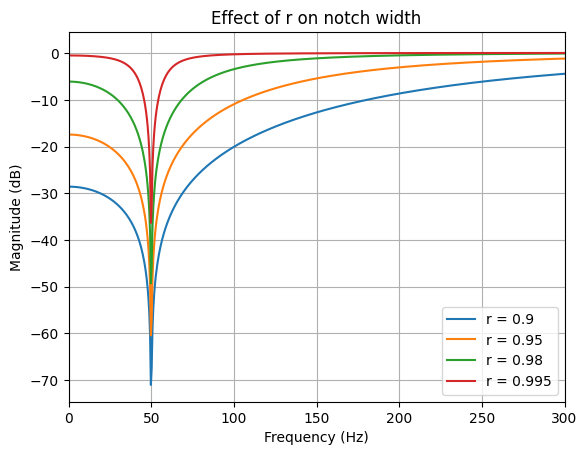

In [ ]:
for r_test in [0.9, 0.95, 0.98, 0.995]:
    a_t = np.array([1, -2*r_test*np.cos(w0), r_test**2])
    w_t, h_t = freqz(b, a_t, worN=16384, fs=Fs)
    plt.plot(w_t, 20*np.log10(np.abs(h_t) + 1e-12), label=f"r = {r_test}")

plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.title("Effect of r on notch width")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.show()